### Universidad Católica "Nuestra Señora de la Asunción"
### Facultad de Ciencias y Tecnología
---

#**Telecomunicaciones 1**

#*FM modulation analysis: Frecuencia Modulada*

**Autor:** Elías Álcarez

**Fecha:** 21/03/2025

#Funciones graficadoras

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler
from itertools import cycle

def fft_analysis(signal, fs):
    n = len(signal)
    freq = np.fft.fftshift(np.fft.fftfreq(n, 1/fs))
    mag = np.fft.fftshift(np.abs(np.fft.fft(signal)))
    return freq, mag

def smart_plotter(groups, t, fs):
    plt.rcParams.update({
        'axes.grid': True,
        'grid.linestyle': '--',
        'grid.alpha': 0.4,
        'axes.axisbelow': True,  # Grid detrás de los datos
        'axes.prop_cycle': cycler(color=plt.cm.tab10.colors) * cycler(linestyle=['-', '--', '-.', ':'])
    })

    for group in groups:
        fig, ax = plt.subplots(1, 2, figsize=(14, 5))
        fig.suptitle(group['title'], fontsize=14, fontweight='bold')

        # Configuración por defecto
        config = {
            'time': {'legend': 'best', 'xlim': (t[0], t[-1]), 'ylim': None},
            'freq': {'legend': 'best', 'xlim': (-fs/2, fs/2), 'ylim': None}
        }

        # Actualizar configuración personalizada
        if 'config' in group:
            for domain in ['time', 'freq']:
                config[domain].update(group['config'].get(domain, {}))

        # Graficar señales
        for signal_info in group['signals']:
            data = signal_info[0]
            label = signal_info[1]
            style = signal_info[2] if len(signal_info) > 2 else '-'

            # Dominio temporal
            line = ax[0].plot(t, data, style, label=label)[0]
            color = line.get_color()  # Color como string o tupla

            # Dominio frecuencial
            freq, mag = fft_analysis(data, fs)

            # Configurar estilo para stems
            stem_style = style[1:] if len(style) > 1 else '-'

            # Usar color y estilo por separado
            markerline, stemlines, baseline = ax[1].stem(
                freq, mag,
                linefmt=color + stem_style,  # Aplicar estilo aquí
                markerfmt=' ',
                basefmt=color+ stem_style,
                label=label
            )

        # Configuración de ejes
        ax[0].set(xlabel='Tiempo (s)', ylabel='Amplitud',
                 xlim=config['time']['xlim'], ylim=config['time']['ylim'],
                 title='Dominio Temporal')
        ax[1].set(xlabel='Frecuencia (Hz)', ylabel='Magnitud',
                 xlim=config['freq']['xlim'], ylim=config['freq']['ylim'],
                 title='Dominio Frecuencial')

        # Añadir grids y leyendas
        for i, domain in enumerate(['time', 'freq']):
            ax[i].grid(True, which='both', linestyle='--', alpha=0.4)
            ax[i].minorticks_on()
            ax[i].legend(loc=config[domain]['legend'])

        plt.tight_layout()
        plt.show()
def smart_plotter_time(groups, t):
    plt.rcParams.update({
        'axes.grid': True,
        'grid.linestyle': '--',
        'grid.alpha': 0.4,
        'axes.axisbelow': True,
        'axes.prop_cycle': cycler(color=plt.cm.tab10.colors) * cycler(linestyle=['-', '--', '-.', ':'])
    })

    for group in groups:
        fig, ax = plt.subplots(figsize=(10, 5))
        fig.suptitle(group['title'], fontsize=14, fontweight='bold')

        # Configuración por defecto
        config = {
            'legend': 'best',
            'xlim': (t[0], t[-1]),
            'ylim': None
        }

        # Actualizar configuración personalizada si está presente
        if 'config' in group:
            config.update(group['config'].get('time', {}))

        # Graficar señales en el dominio temporal
        for signal_info in group['signals']:
            data = signal_info[0]
            label = signal_info[1]
            style = signal_info[2] if len(signal_info) > 2 else '-'
            ax.plot(t,data, style, label=label)

        # Configurar ejes
        ax.set(
            xlabel='Tiempo (s)',
            ylabel='Amplitud',
            xlim=config['xlim'],
            ylim=config['ylim'],
            title='Dominio Temporal'
        )

        ax.grid(True, which='both', linestyle='--', alpha=0.4)
        ax.minorticks_on()
        ax.legend(loc=config['legend'])

        plt.tight_layout()
        plt.show()


def smart_plotter_freq(groups, fs):
    plt.rcParams.update({
        'axes.grid': True,
        'grid.linestyle': '--',
        'grid.alpha': 0.4,
        'axes.axisbelow': True,
        'axes.prop_cycle': cycler(color=plt.cm.tab10.colors)
    })

    for group in groups:
        fig, ax = plt.subplots(figsize=(10, 5))
        fig.suptitle(group['title'], fontsize=14, fontweight='bold')

        # Configuración por defecto
        config = {
            'freq': {'legend': 'best', 'xlim': (-fs/2, fs/2), 'ylim': None}
        }

        if 'config' in group:
            config['freq'].update(group['config'].get('freq', {}))

        for signal_info in group['signals']:
            data = signal_info[0]
            label = signal_info[1]
            style = signal_info[2] if len(signal_info) > 2 else '-'
            show_stemlines = signal_info[3] if len(signal_info) > 3 else False  # Nuevo parámetro

            # Extraer color del estilo (e.g., 'g-' -> 'g')
            color = style[0] if style else plt.rcParams['axes.prop_cycle'].by_key()['color'][0]
            linestyle = style[1:] if len(style) > 1 else ''

            # Dominio frecuencial
            freq, mag = fft_analysis(data, fs)

            # Graficar los marcadores
            markerline, stemlines, baseline = ax.stem(
                freq, mag,
                linefmt=color,  # Sin líneas verticales por defecto
                markerfmt='.',  # Marcadores
                basefmt=color,  # Sin línea base por defecto
                label=label
            )

            # Aplicar color personalizado
            plt.setp(markerline, 'color', color)
            plt.setp(markerline, 'markerfacecolor', color)
            plt.setp(markerline, 'markeredgecolor', color)

            # Mostrar u ocultar stemlines y baseline según el parámetro
            if show_stemlines:
                plt.setp(markerline, 'visible', False)
                plt.setp(stemlines, 'color', color)
                plt.setp(stemlines, 'linestyle', linestyle)
                #plt.setp(baseline, 'visible', False)
            else:

                plt.setp(stemlines, 'visible', False)
                plt.setp(baseline, 'visible', False)
        ax.set(
            xlabel='Frecuencia (Hz)',
            ylabel='Magnitud',
            xlim=config['freq']['xlim'],
            ylim=config['freq']['ylim'],
            title='Dominio Frecuencial'
        )

        ax.grid(True, which='both', linestyle='--', alpha=0.4)
        ax.minorticks_on()
        ax.legend(loc=config['freq']['legend'])

        plt.tight_layout()
        plt.show()


#1)Generación de Señales FM

$s(t) = A_c \cos \left(  2\pi f_c t +2\pi k_f \int_0^t m(\tau) d\tau \right)$

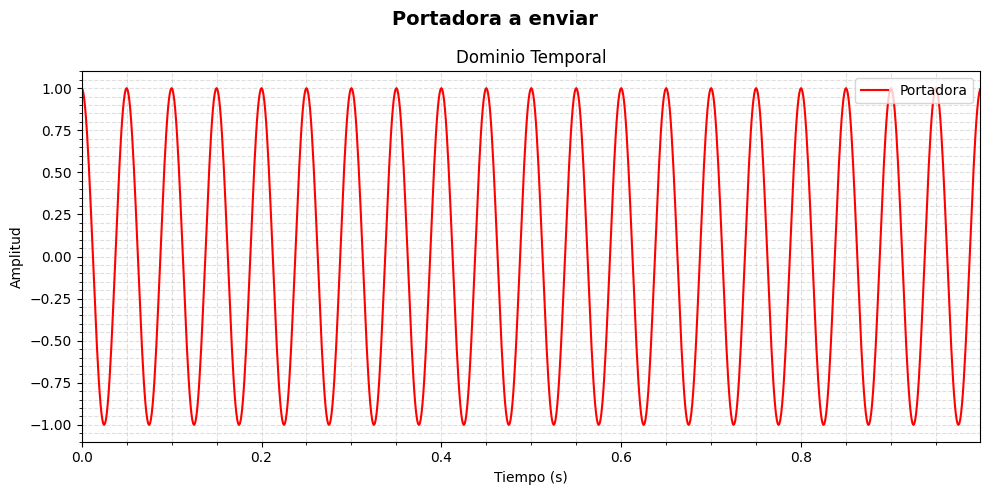

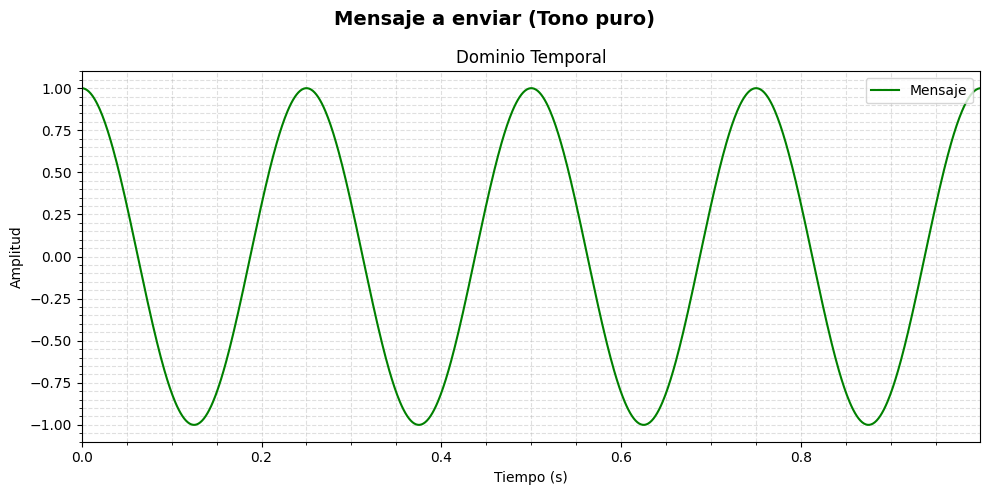

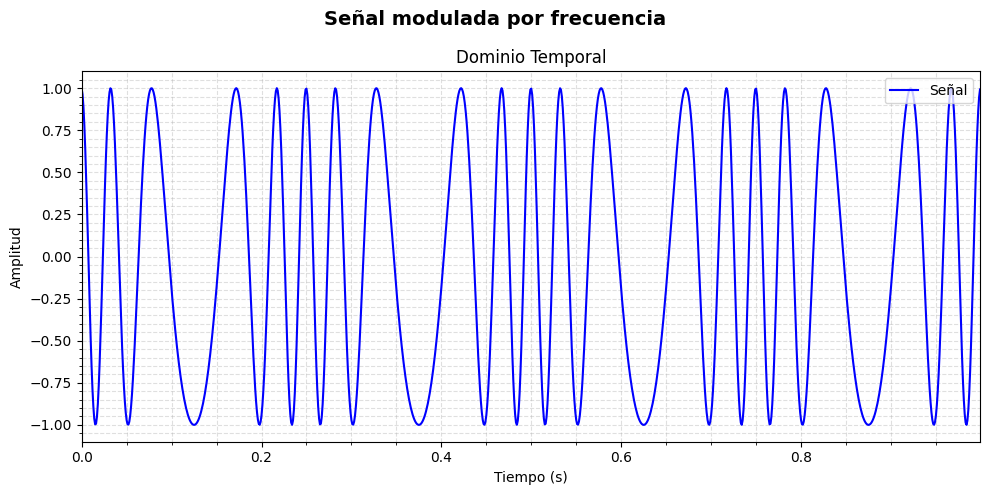

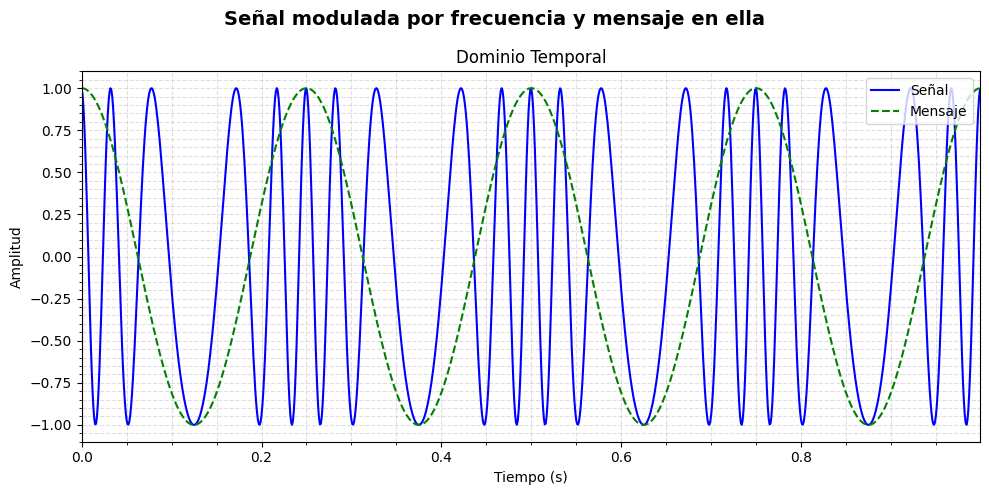

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# === Parámetros básicos ===
fc = 20           # Frecuencia de la portadora (Hz)
fm = 4            # Frecuencia del mensaje (Hz)
T = 1             # Duración total (s)
Ts = 0.001        # Tiempo de muestreo (s)
fs = 1 / Ts       # Frecuencia de muestreo (Hz)
t = np.arange(0, T, Ts)  # Vector temporal

# === Parámetros de modulación ===
beta = 3          # Índice de modulación
Ac = 1            # Amplitud de la portadora
Am = 1            # Amplitud del mensaje
kf = beta * fm / Am       # Sensibilidad del modulador
delta_f = Am * kf         # Desviación máxima de frecuencia

# === Señales base ===
c = Ac * np.cos(2 * np.pi * fc * t)          # Portadora
m = Am * np.cos(2 * np.pi * fm * t)          # Mensaje

# === Señal modulada en frecuencia (FM) ===
int_m = Ts * np.cumsum(m)                    # Integral discreta del mensaje
s = Ac * np.cos(2 * np.pi * fc * t + 2 * np.pi * kf * int_m)  # Señal FM

# === Estructuras para graficar con smart_plotter_time ===
portadora = {
    'title': "Portadora a enviar",
    'signals': [
        (c, "Portadora", 'r-'),
    ],
    'config': {
        'time': {'legend': 'upper right'},
        'freq': {'xlim': (-30, 30), 'legend': 'upper left'}
    }
}

mensaje = {
    'title': "Mensaje a enviar (Tono puro)",
    'signals': [
        (m, "Mensaje", 'g-'),
    ],
    'config': {
        'time': {'legend': 'upper right'},
        'freq': {'xlim': (-30, 30), 'legend': 'upper left'}
    }
}

senal = {
    'title': "Señal modulada por frecuencia",
    'signals': [
        (s, "Señal", 'b-'),
    ],
    'config': {
        'time': {'legend': 'upper right'},
        'freq': {'xlim': (-50, 50), 'legend': 'upper left'}
    }
}

grupo1 = {
    'title': "Señal modulada por frecuencia y mensaje en ella",
    'signals': [
        (s, "Señal", 'b-'),
        (m, "Mensaje", 'g--'),
        # (c, "Portadora", 'r:')  # Podés descomentar si querés agregarla
    ],
    'config': {
        'time': {'legend': 'upper right'},
        'freq': {'xlim': (-50, 50), 'legend': 'upper left'}
    }
}

# === Graficar todo ===
smart_plotter_time([portadora, mensaje, senal, grupo1], t)


#2)Espectro de Señales FM:

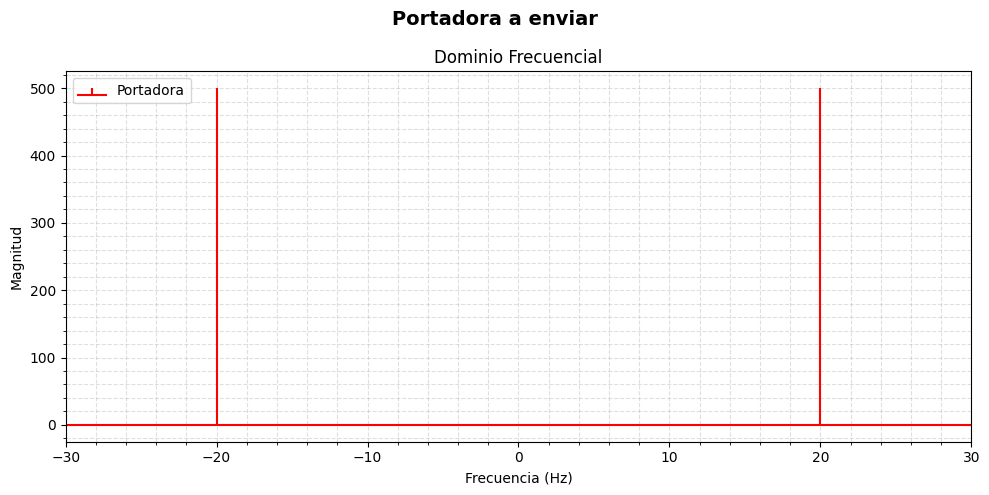

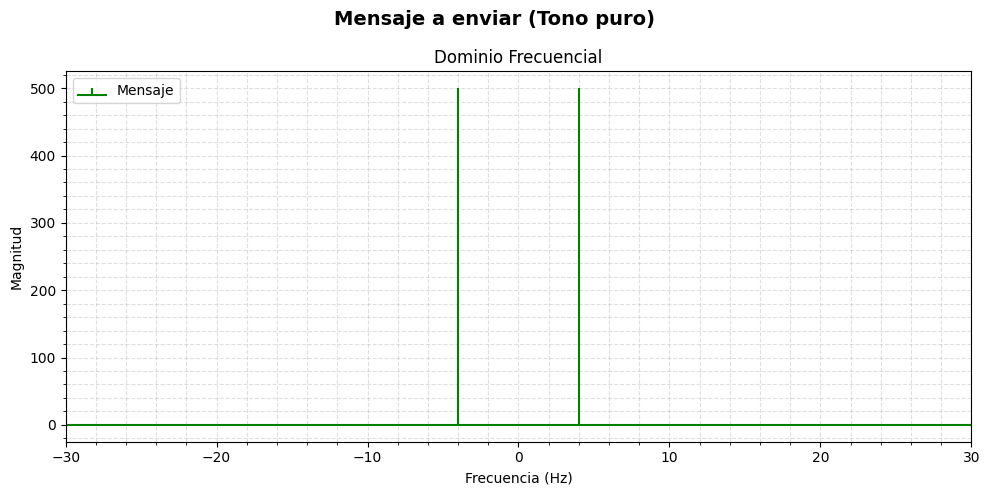

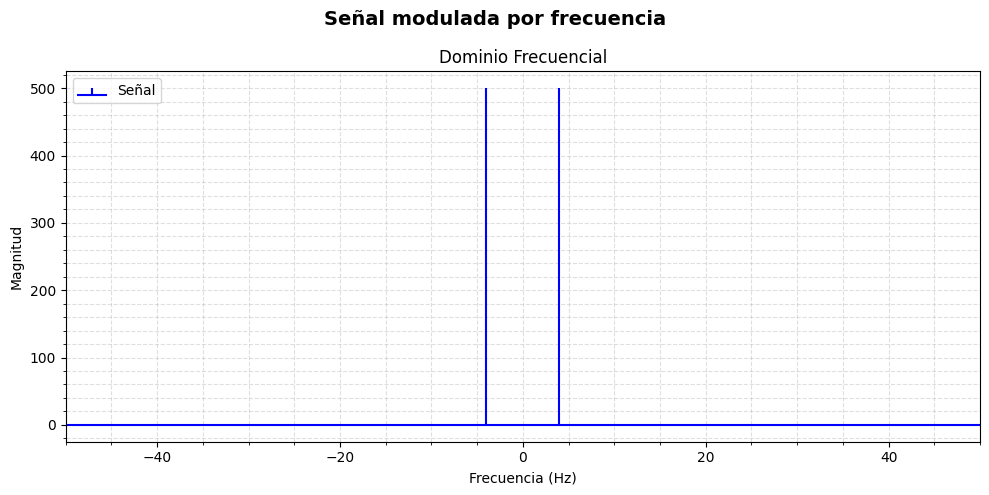

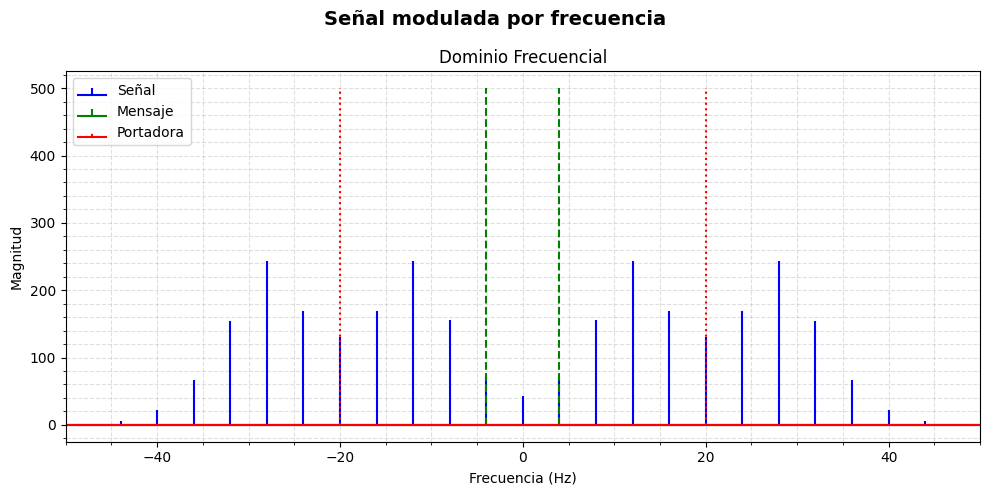

In [ ]:
portadora_triangulo = {
    'title': "Portadora a enviar",
    'signals': [
        (c, "Portadora", 'r-', True),  # Señal portadora en rojo, líneas verticales en el espectro activadas (True)
    ],
    'config': {
        'time': {'legend': 'upper right'},  # Leyenda ubicada arriba a la derecha en el gráfico temporal
        'freq': {'xlim': (-30, 30), 'legend': 'upper left'}  # Rango de frecuencias y leyenda en gráfico espectral
    }
}

mensaje_triangulo = {
    'title': "Mensaje a enviar (Tono puro)",
    'signals': [
        (m, "Mensaje", 'g-', True),  # Mensaje senoidal en verde, con stems activados
    ],
    'config': {
        'time': {'legend': 'upper right'},
        'freq': {'xlim': (-30, 30), 'legend': 'upper left'}
    }
}

senal_triangulo = {
    'title': "Señal modulada por frecuencia",
    'signals': [
        (m, "Señal", 'b-', True),  # OJO: esta línea está graficando 'm' en lugar de 's' (si es intencional, todo bien)
    ],
    'config': {
        'time': {'legend': 'upper right'},
        'freq': {'xlim': (-50, 50), 'legend': 'upper left'}
    }
}

grupo1 = {
    'title': "Señal modulada por frecuencia",
    'signals': [
        (s, "Señal", 'b-', True),     # Señal FM modulada en azul, con stems
        (m, "Mensaje", 'g--', True),  # Mensaje original con línea verde punteada, stems activados
        (c, "Portadora", 'r:', True)  # Portadora en rojo punteado, con stems
    ],
    'config': {
        'time': {'legend': 'upper right'},
        'freq': {'xlim': (-50, 50), 'legend': 'upper left'}
    }
}

smart_plotter_freq([portadora_triangulo, mensaje_triangulo, senal_triangulo, grupo1], fs)


##Extra 1: Frecuencia y Tiempo:

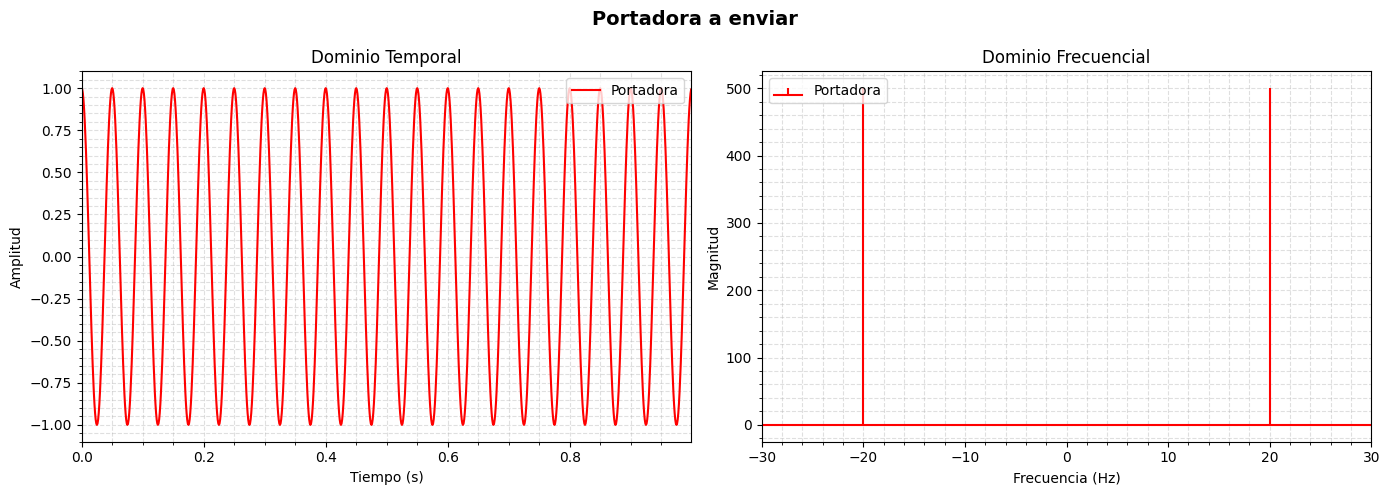

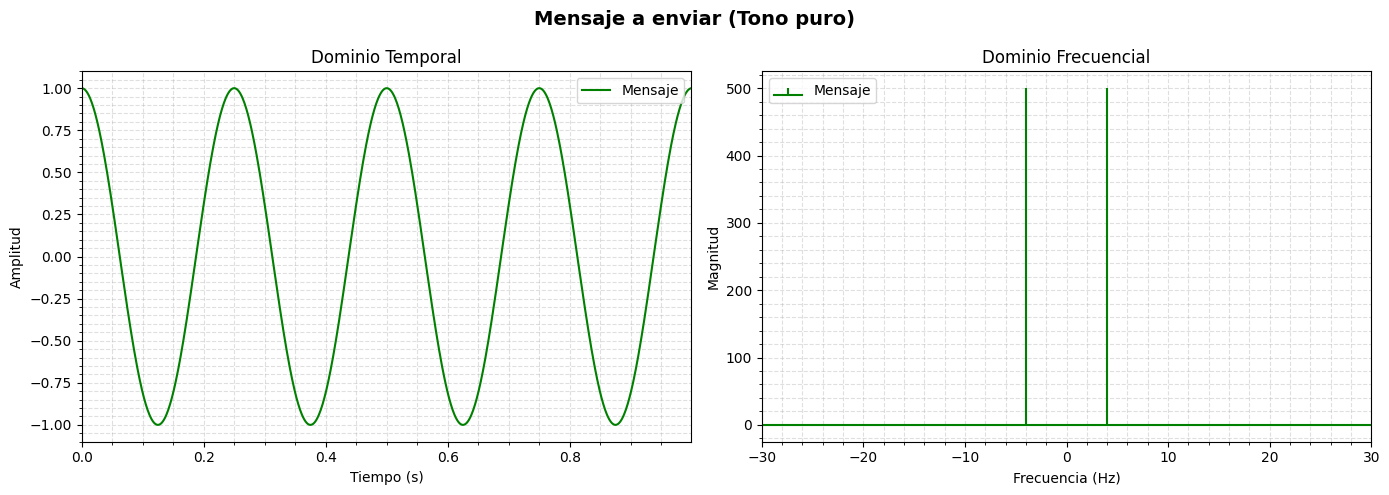

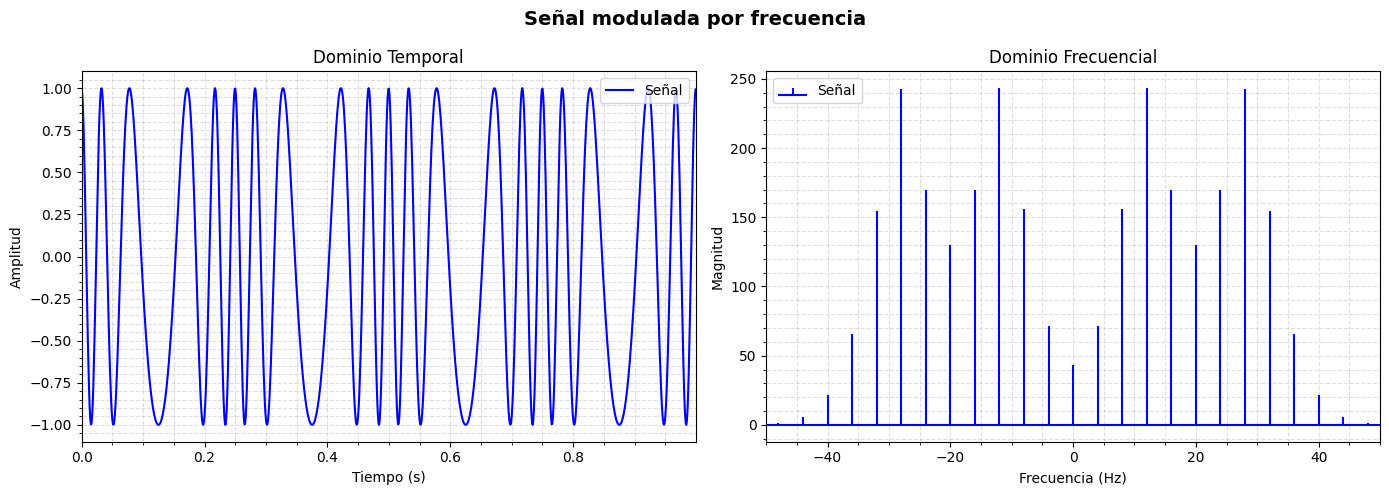

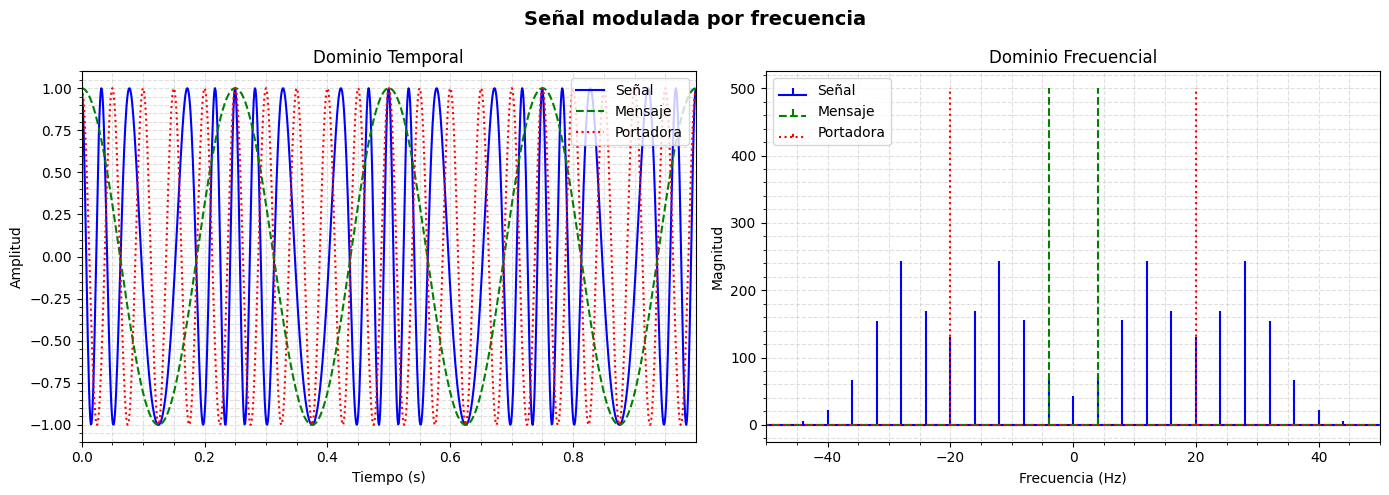

In [ ]:
grupo1 ={
    'title': "Señal modulada por frecuencia",
    'signals': [
        (s, "Señal", 'b-',True),
        (m, "Mensaje", 'g--',True),
        (c, "Portadora", 'r:',True)
    ],
    'config': {
        'time': {'legend': 'upper right'},
        'freq': {'xlim': (-50, 50), 'legend': 'upper left'}
    }
}
smart_plotter([portadora,mensaje,senal,grupo1],t,fs)

##Extra 2: Espectro de un mensaje triangular en la frecuencia:

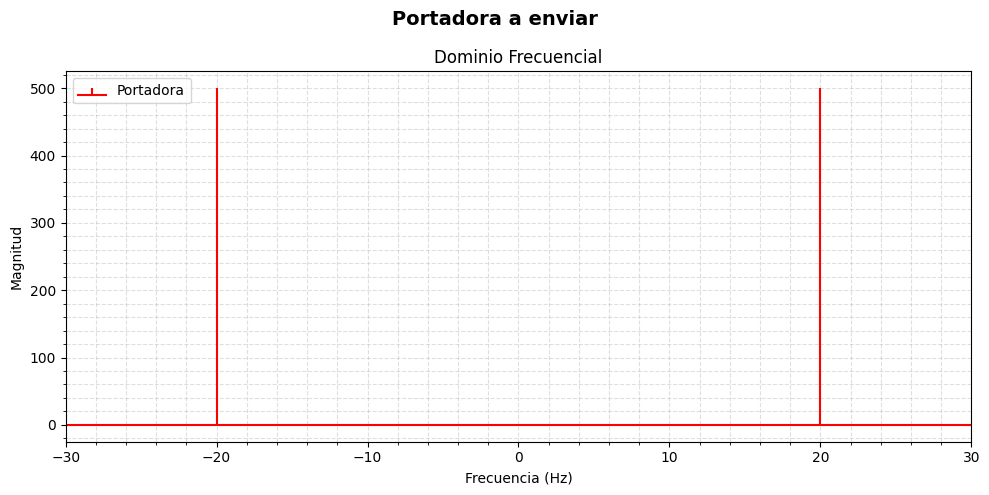

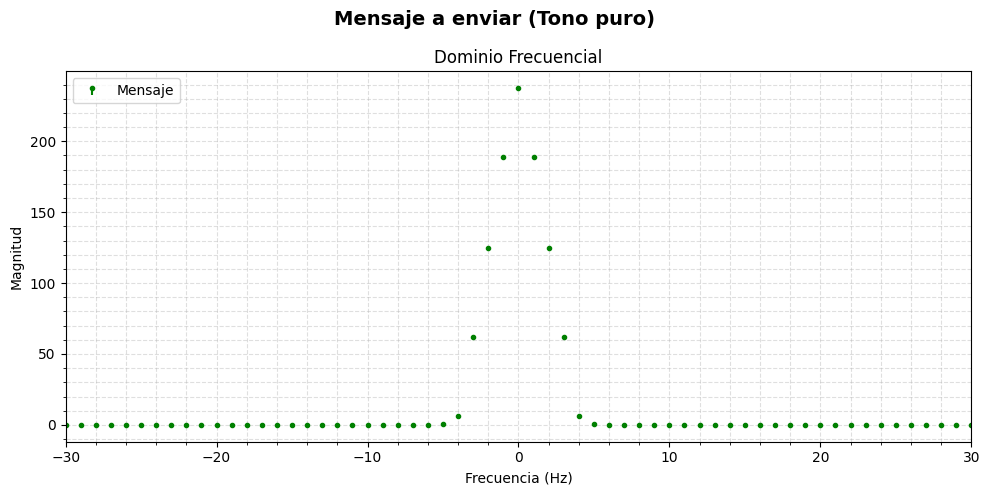

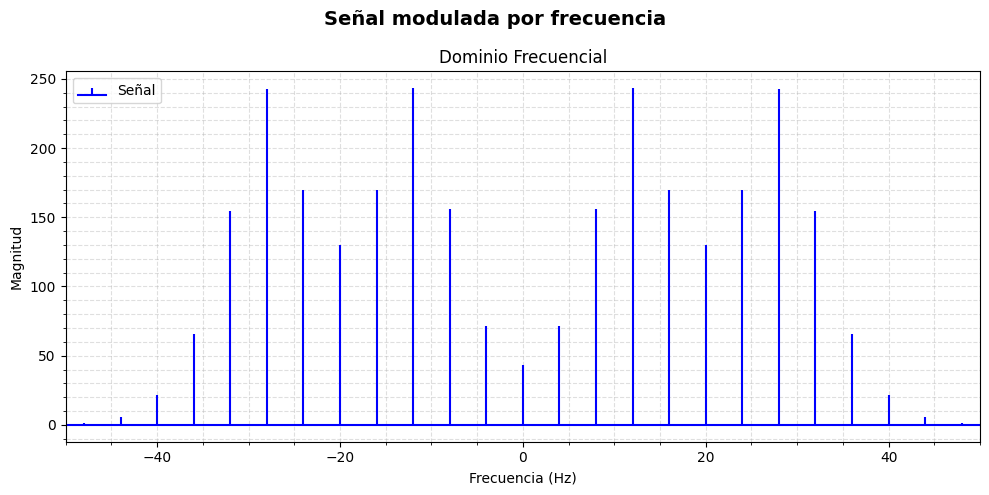

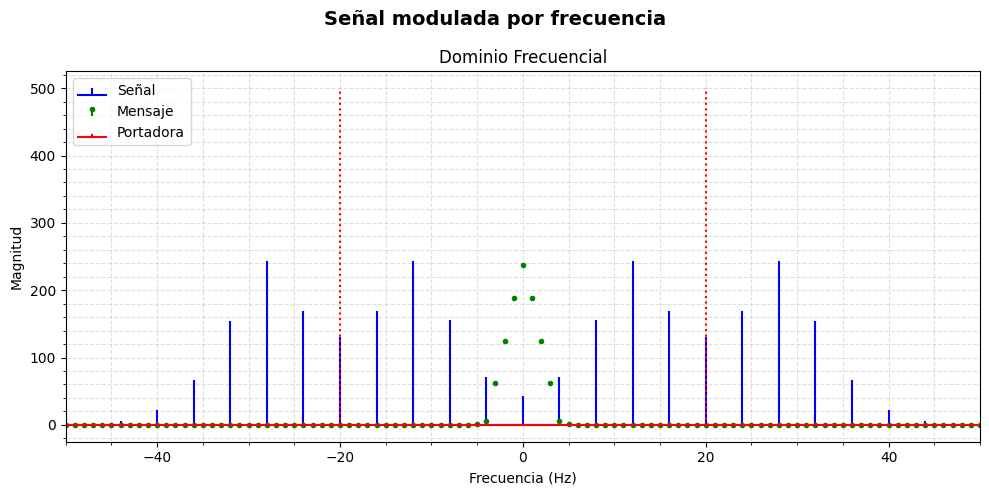

In [ ]:
m_triag = np.sinc(fm * (t-T/2))**2
int_m_triag = Ts*np.cumsum(m_triag)
s_triag = Ac*np.cos(2*np.pi*fc*t + 2*np.pi*kf*int_m)


portadora_triangulo = {
    'title': "Portadora a enviar",
    'signals': [
        (c, "Portadora", 'r-',True),
    ],
    'config': {
        'time': {'legend': 'upper right'},
        'freq': {'xlim': (-30, 30), 'legend': 'upper left'}
    }
}

mensaje_triangulo ={
    'title': "Mensaje a enviar (Tono puro)",
    'signals': [
        (m_triag, "Mensaje", 'g-',False),
    ],
    'config': {
        'time': {'legend': 'upper right'},
        'freq': {'xlim': (-30, 30), 'legend': 'upper left'}
    }
}

senal_triangulo ={
    'title': "Señal modulada por frecuencia",
    'signals': [
        (s_triag, "Señal", 'b-',True),
    ],
    'config': {
        'time': {'legend': 'upper right'},
        'freq': {'xlim': (-50, 50), 'legend': 'upper left'}
    }
}

grupo1 ={
    'title': "Señal modulada por frecuencia",
    'signals': [
        (s_triag, "Señal", 'b-',True),
        (m_triag, "Mensaje", 'g--',False),
        (c, "Portadora", 'r:',True)
    ],
    'config': {
        'time': {'legend': 'upper right'},
        'freq': {'xlim': (-50, 50), 'legend': 'upper left'}
    }
}

smart_plotter_freq([portadora_triangulo,mensaje_triangulo,senal_triangulo,grupo1],fs)





##Ancho de banda

In [ ]:
BW = 2 * delta_f + 2 * fm  # Regla de Carlson: BW ≈ 2·Δf + 2·fm
print(f"Mediante la regla de Carlson, el ancho de banda se estima en {BW} Hz.")


Mediante la regla de Carlson, el ancho de banda se estima en 32.0 Hz.


#3)Demodulación

##Método 1:

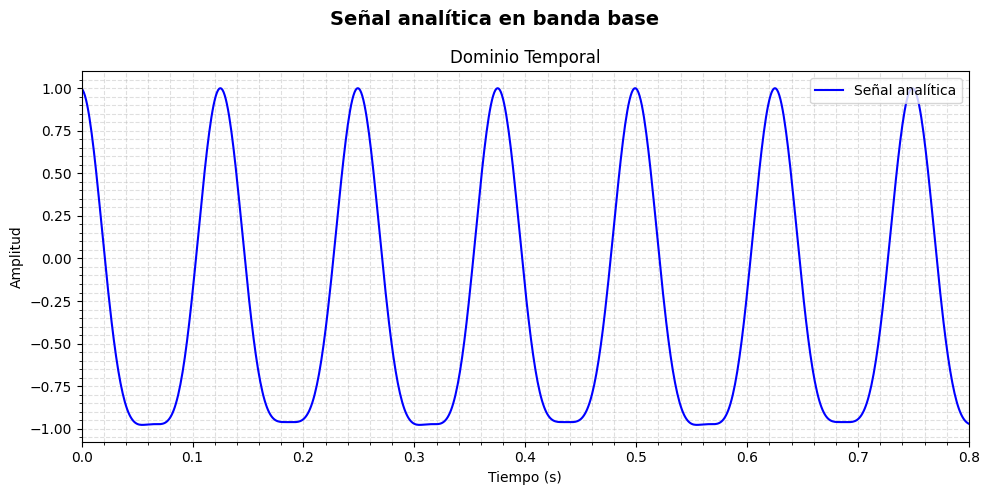

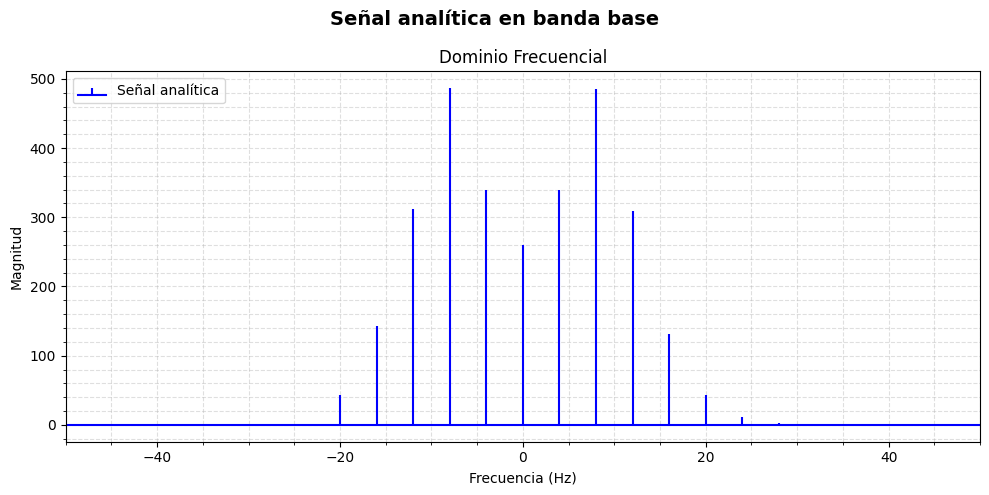

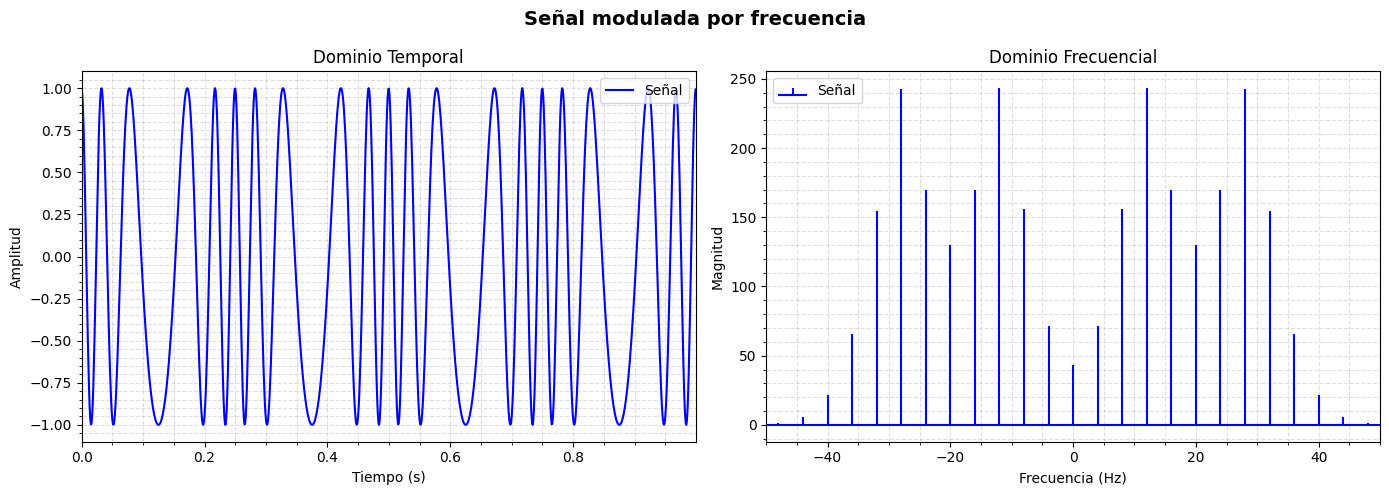

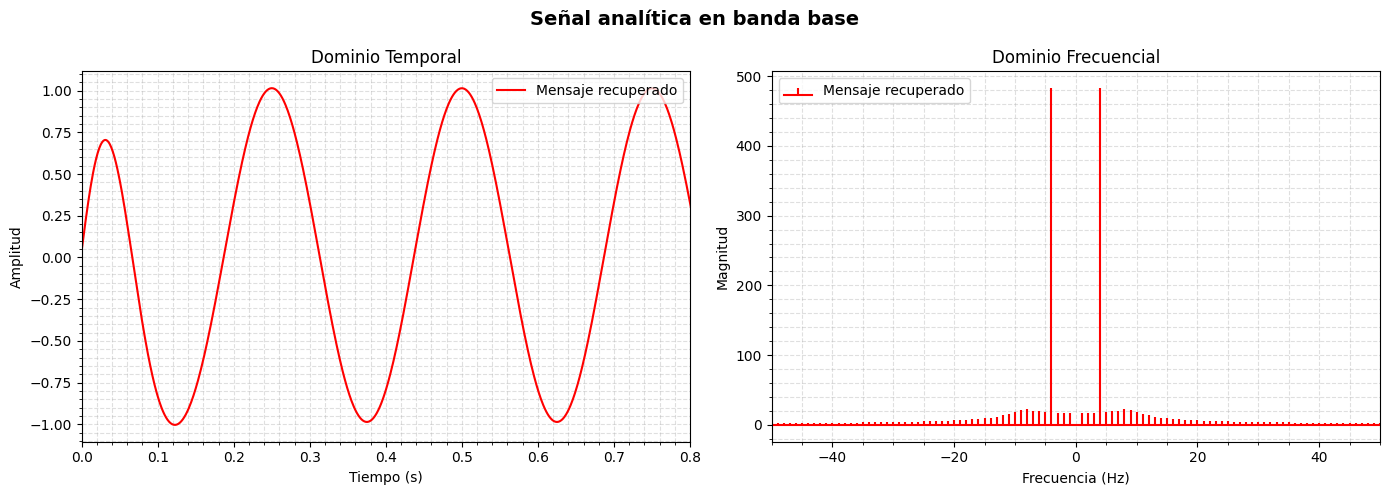

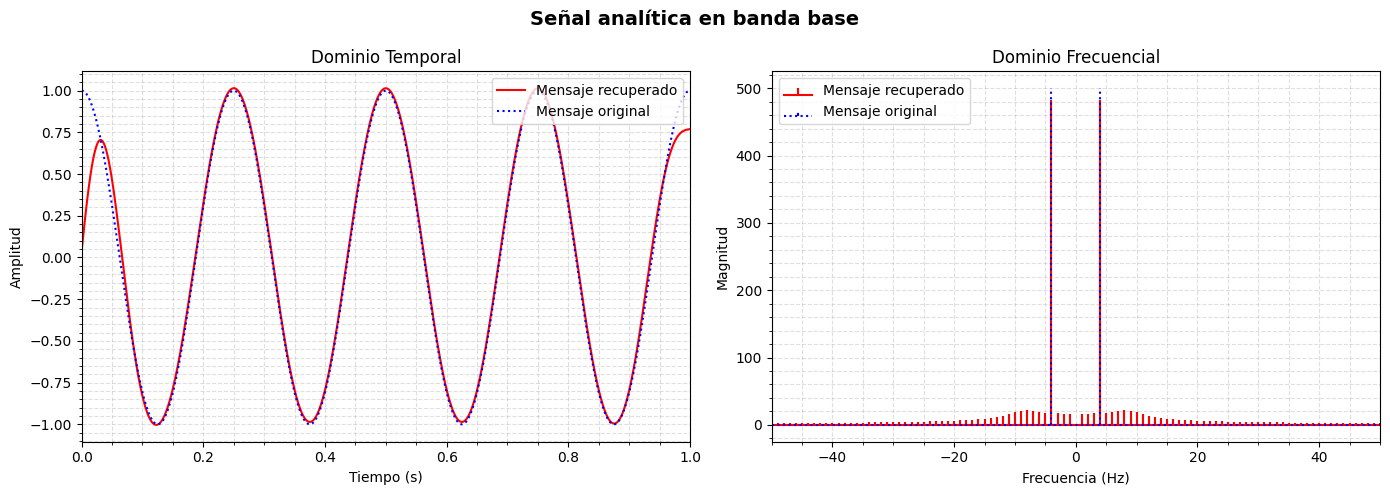

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt

# === Señal analítica: aplicación de la transformada de Hilbert y paso a banda base ===
yq = hilbert(s) * np.exp(-1j * 2 * np.pi * fc * t)  # yq: señal compleja en banda base

# === Derivada del ángulo: obtención de la frecuencia instantánea ===
phi = 0
phi = np.append(phi, np.diff(np.unwrap(np.angle(yq))) / Ts)  # Derivada discreta de fase

# === Filtro pasa bajas para limpiar la señal recuperada ===
'''
def lowpass_filter(signal, fs, cutoff=10, order=4):
    b, a = butter(order, cutoff / (0.5 * fs), btype='low')  # Diseño de filtro Butterworth
    return filtfilt(b, a, signal)  # Filtro sin fase (aplicado hacia adelante y atrás)

z = lowpass_filter((1 / (2 * np.pi * kf)) * phi, fs, cutoff=10)  # Escalado y filtrado
'''
z = z - np.mean(z)  # Corrección de offset DC

# === Gráficos ===

analitica_abs = {
    'title': "Señal analítica en banda base",
    'signals': [
        (np.abs(yq), "Señal analítica", 'b-'),  # Módulo de la señal analítica (envolvente)
    ],
    'config': {
        'time': {'xlim': (0, 0.8), 'legend': 'upper right'},
        'freq': {'xlim': (-50, 50), 'legend': 'upper left'}
    }
}

analitica = {
    'title': "Señal analítica en banda base",
    'signals': [
        (yq, "Señal analítica", 'b-', True),  # Señal analítica compleja en azul
    ],
    'config': {
        'time': {'xlim': (0, 0.8), 'legend': 'upper right'},
        'freq': {'xlim': (-50, 50), 'legend': 'upper left'}
    }
}

mensaje_recuperado = {
    'title': "Señal analítica en banda base",
    'signals': [
        (z, "Mensaje recuperado", 'r-'),  # Mensaje demodulado (en rojo)
    ],
    'config': {
        'time': {'xlim': (0, 0.8), 'legend': 'upper right'},
        'freq': {'xlim': (-50, 50), 'legend': 'upper left'}
    }
}

grupo1 = {
    'title': "Señal analítica en banda base",
    'signals': [
        (z - np.mean(z), "Mensaje recuperado", 'r-'),  # Eliminación de offset
        (m, "Mensaje original", 'b:')  # Mensaje original en azul punteado para comparar
    ],
    'config': {
        'time': {'xlim': (0, 1), 'legend': 'upper right'},
        'freq': {'xlim': (-50, 50), 'legend': 'upper left'}
    }
}

# === Mostrar gráficos ===
smart_plotter_time([analitica], t)
smart_plotter_freq([analitica], fs)
smart_plotter([senal, mensaje_recuperado, grupo1], t, fs)


#Tarea


###Enunciado

Calculo de potencias:

Calculemos las potencias de las señales del mensaje, la portadora y de las señal Fm modulada, de manera analítica y numérica.

###Solución Analítica

La potencia de una señal senoiral está definida como:
$\frac{A^2}{2}$
Por lo que la potencia del mensaje y la portadora son las siguientes:

$P_m = \frac{A_m^2}{2},$
$P_c = \frac{A_c^2}{2}$

Para una señal FM la potencia se concentra en la portadora, por lo que

$P_s = P_c = \frac{A_c^2}{2}$



###Solución numérica


Numericamente, podemos aproximar
$P = \frac{1}{T}\int_Ty^2(t)dt\approx \frac{1}{N}\sum_N y^2[n]$
Esto se puede conseguir mediante un promedio del cuadrado de los términos de la función

In [ ]:
# === Cálculo de potencias ===

# Potencias analíticas
Pm_analitico = Am**2 / 2
Pc_analitico = Ac**2 / 2
Ps_analitico = Ac**2 / 2  # En FM, la potencia no cambia porque la envolvente es constante

# Potencias numéricas: promedio de la señal al cuadrado
Pm_numerico = np.mean(m**2)
Pc_numerico = np.mean(c**2)
Ps_numerico = np.mean(s**2)

# Mostrar resultados
print("=== Potencias (analíticas vs numéricas) ===")
print(f"Mensaje:     {Pm_analitico:.4f} (analítica) vs {Pm_numerico:.4f} (numérica)")
print(f"Portadora:   {Pc_analitico:.4f} (analítica) vs {Pc_numerico:.4f} (numérica)")
print(f"FM señal:    {Ps_analitico:.4f} (analítica) vs {Ps_numerico:.4f} (numérica)")

# Cálculo del error absoluto
print("\n=== Error absoluto ===")
print(f"Mensaje     Error = {abs(Pm_analitico - Pm_numerico):.4e}")
print(f"Portadora   Error = {abs(Pc_analitico - Pc_numerico):.4e}")
print(f"FM          Error = {abs(Ps_analitico - Ps_numerico):.4e}")


=== Potencias (analíticas vs numéricas) ===
Mensaje:     0.5000 (analítica) vs 0.5000 (numérica)
Portadora:   0.5000 (analítica) vs 0.5000 (numérica)
FM señal:    0.5000 (analítica) vs 0.5035 (numérica)

=== Error absoluto ===
Mensaje     Error = 1.6653e-16
Portadora   Error = 0.0000e+00
FM          Error = 3.4783e-03
